<a href="https://colab.research.google.com/github/sjschooley/SDS510/blob/main/Mod_6_badge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

I used the code from 6.2 and 6.3, Ladd et al.'s tutorial, and Google for this assignment.

From UCINET:

DESCRIPTION: Data refers to four groups involved in cocaine trafficking in Spain. Information comes from police wiretapping and meetings registered by police investigations of these criminal organisations between 2007 and 2009.

I chose to use the Juanes subset, since it was the largest of the four.

Again, UCINET:

Operation JUANES (N=51). In 2009, the police investigation detected a group involved in the smuggling of cocaine from Mexico to be distributed in Madrid (Spain). In this case, the group operated in close cooperation with another organization that was laundering the illegal income from drug distribution from this and other groups. The cocaine traffickers earned an estimated EUR 60 million.

In [1]:
import networkx as nx
import pandas as pd
import csv
from zipfile import ZipFile
import io

In [3]:
with ZipFile('Cocaine Smuggling CSV.zip', 'r') as archive:
    with archive.open('CSV/COCAINE_JUANES.csv', 'r') as f:
        juanestext = f.read().decode('utf-8')

In [4]:
juanestext

'\ufeff"",6D,ABF,AFPG,AHM,ARS,CAPV,CH,CL,CMP,DEAR,DFM,DLLS,DN,EGM,EHJ,EO,FARP,FDS,FGV,FP,GEBA,IN,INB,ING,IS,JATC,JAVM,JBH,JC,JDQJ,JHRR,JJLH,JJVL,JLLO,JLPC,JLRL,JLT,LGM,MDAA,MIAP,MO,MRG,OAMS,OJMG,OJSR,RF,RJZZ,RMM,RMP,SB,V\r\n6D,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0\r\nABF,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,1,0,0,0,1,0,1,0,1,0,1,0,0\r\nAFPG,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0\r\nAHM,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0\r\nARS,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0\r\nCAPV,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0,1,0,1\r\nCH,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0\r\nCL,0,0,0,0,0,

In [5]:
df = pd.read_csv(io.StringIO(juanestext), index_col=0)

In [6]:
G = nx.from_pandas_adjacency(df)

In [7]:
print(G)

Graph with 51 nodes and 93 edges


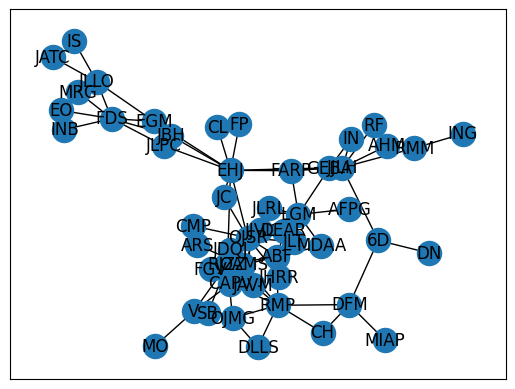

In [8]:
nx.draw_networkx(G)

It looks like the graph is connected (which makes sense for a smuggling network).  It also looks sparse.  To verify:

In [9]:
density = nx.density(G)
density

0.07294117647058823

In [10]:
print(nx.is_connected(G))

True


In [ ]:
triadclos = nx.transitivity(G)
triadclos

0.27435387673956263

So it seems like it is less likely that these nodes are interconnected--that the people in the triangles know each other.  That doesn't matter, except that it might mean there's less redundancy in the network, which could be helpful if we were trying to break it up.

It sounds like info doesn't work anymore, so you have to calculate the average degree of the graphy manually.

In [11]:
degree_dict = dict(G.degree(G.nodes()))
nx.set_node_attributes(G, degree_dict, 'degree')

In [12]:
print(f"Average degree: {sum(dict(G.degree()).values()) / G.number_of_nodes():.2f}")

Average degree: 3.65


Now, to think about who would be a good candidate for a "Netflix subscription."

In [13]:
from operator import itemgetter

In [14]:
sorted_degree = sorted(degree_dict.items(), key=itemgetter(1), reverse=True)
sorted_degree

[('OJSR', 16),
 ('EHJ', 10),
 ('LGM', 10),
 ('OAMS', 9),
 ('RJZZ', 9),
 ('ABF', 8),
 ('JJLH', 8),
 ('RMP', 8),
 ('CAPV', 7),
 ('FDS', 7),
 ('JJVL', 5),
 ('JLLO', 5),
 ('OJMG', 5),
 ('V', 5),
 ('DFM', 4),
 ('JDQJ', 4),
 ('6D', 3),
 ('DEAR', 3),
 ('EGM', 3),
 ('FARP', 3),
 ('FGV', 3),
 ('GEBA', 3),
 ('JAVM', 3),
 ('JBH', 3),
 ('JLPC', 3),
 ('JLRL', 3),
 ('JLT', 3),
 ('SB', 3),
 ('CH', 2),
 ('DLLS', 2),
 ('IN', 2),
 ('JC', 2),
 ('MDAA', 2),
 ('MRG', 2),
 ('RMM', 2),
 ('AFPG', 1),
 ('AHM', 1),
 ('ARS', 1),
 ('CL', 1),
 ('CMP', 1),
 ('DN', 1),
 ('EO', 1),
 ('FP', 1),
 ('INB', 1),
 ('ING', 1),
 ('IS', 1),
 ('JATC', 1),
 ('JHRR', 1),
 ('MIAP', 1),
 ('MO', 1),
 ('RF', 1)]

Okay, the top three nodes in terms of how many other nodes they are connected to, are:

*   OJSR 16
*   EHJ 10
*   LGM 10

OJSR is the clear winner here, but let's also keep EHJ and LGM in mind.

Now to look at who the most important brokers in the network are.

In [15]:
betweenness_dict = nx.betweenness_centrality(G)
eigenvector_dict = nx.eigenvector_centrality(G)

In [16]:
nx.set_node_attributes(G, betweenness_dict, 'betweenness')
nx.set_node_attributes(G, eigenvector_dict, 'eigenvector')

In [17]:
sorted_betweenness = sorted(betweenness_dict.items(), key=itemgetter(1), reverse=True)
sorted_betweenness

[('EHJ', 0.49544217687074826),
 ('OJSR', 0.29578943958535797),
 ('JJLH', 0.2638775510204082),
 ('RJZZ', 0.17674700356333004),
 ('EGM', 0.15061224489795919),
 ('LGM', 0.1128513119533528),
 ('FDS', 0.11204081632653061),
 ('RMP', 0.11089018464528673),
 ('6D', 0.08819047619047617),
 ('JLLO', 0.08795918367346939),
 ('DFM', 0.07521088435374149),
 ('OAMS', 0.066319403952057),
 ('ABF', 0.06524457402008421),
 ('JBH', 0.04183673469387755),
 ('JLPC', 0.04183673469387755),
 ('V', 0.04136054421768708),
 ('RMM', 0.04),
 ('CAPV', 0.03384904437965663),
 ('FARP', 0.02979591836734694),
 ('OJMG', 0.02880596047942986),
 ('GEBA', 0.027442176870748302),
 ('JAVM', 0.009604146420472953),
 ('JJVL', 0.00614382896015549),
 ('JDQJ', 0.0005986394557823129),
 ('AFPG', 0.0),
 ('AHM', 0.0),
 ('ARS', 0.0),
 ('CH', 0.0),
 ('CL', 0.0),
 ('CMP', 0.0),
 ('DEAR', 0.0),
 ('DLLS', 0.0),
 ('DN', 0.0),
 ('EO', 0.0),
 ('FGV', 0.0),
 ('FP', 0.0),
 ('IN', 0.0),
 ('INB', 0.0),
 ('ING', 0.0),
 ('IS', 0.0),
 ('JATC', 0.0),
 ('JC', 0

So the most important brokers, or connectors on the shortest path between other nodes, are:

*   EHJ 0.49544217687074826
*   OJSR 0.29578943958535797
*   JJLH 0.2638775510204082

EHJ has the highest betweenness centrality by far.  Looks like they are a connection for about half the network.


In [18]:
sorted_eigenvector = sorted(eigenvector_dict.items(), key=itemgetter(1), reverse=True)
sorted_eigenvector

[('OJSR', 0.46448091797719837),
 ('OAMS', 0.3286466668962761),
 ('RJZZ', 0.30578277823322514),
 ('ABF', 0.29695573877835846),
 ('CAPV', 0.27066568950450237),
 ('LGM', 0.2554597026471659),
 ('JJVL', 0.211571624482867),
 ('RMP', 0.19546984211900062),
 ('JDQJ', 0.19474348650804482),
 ('EHJ', 0.1757261248050374),
 ('FGV', 0.16243727288883794),
 ('DEAR', 0.15527669355817247),
 ('JLT', 0.15527669355817247),
 ('JAVM', 0.14746405968634993),
 ('JLRL', 0.14223885889817342),
 ('V', 0.12101530848871578),
 ('OJMG', 0.11488395296279498),
 ('JC', 0.09775822932661232),
 ('MDAA', 0.08435198671503948),
 ('SB', 0.08271279628659221),
 ('FARP', 0.07411775863666305),
 ('CMP', 0.07092470684313297),
 ('JHRR', 0.07092470684313297),
 ('JJLH', 0.0541975214839495),
 ('ARS', 0.05018301929894758),
 ('GEBA', 0.0497072017665145),
 ('DLLS', 0.047389645092479275),
 ('AFPG', 0.039007938435833577),
 ('DFM', 0.038406832086902196),
 ('CH', 0.03571192219160964),
 ('JBH', 0.034943829139349625),
 ('JLPC', 0.034943829139349625

Lastly, to look at who has powerful neighbors.  The three highest scores are:

*   OJSR 0.46448091797719837
*   OAMS 0.3286466668962761
*   RJZZ 0.30578277823322514

OJSR has the highest eigenvector centrality by far.

If there are two "Netflix subscriptions" available, then I would suggest giving them to EHJ and OJSR.  OJSR has the highest degree and eigenvector centrality.  EHJ has the highest betweenness centrality.

If I had to choose only one, I would say EHJ.  They have the second-highest degree, but the highest betweenness.  It looks like about half the network is connected through them, making them the more powerful broker.  To disable the network, I would suggest starting there.

First, let's visualize where EHJ and OJSR are in the network.

In [19]:
colors = ['blue' for n in G]
colors['EHJ'] = 'red'
nx.draw_networkx(G, node_color=colors, with_labels=False)

TypeError: list indices must be integers or slices, not str

I asked Gemini for help with this error.  Here is the explanation:


The error TypeError: list indices must be integers or slices, not str occurred because colors was created as a standard Python list, which only accepts integers (like 0, 1, 2) as indices, not node names like 'EHJ'.

To map colors to nodes correctly in NetworkX, we need to generate a list where the color at each position corresponds to the node at the same position in G.nodes(). I have modified the cell to use a list comprehension that checks the name of each node during generation, coloring 'EHJ' red and all other nodes black.

I understood that I need to use numbers, not node names, to change the color, but I didn't know the number of that node, so wasn't sure how to proceed.  I used Gemini's corrected code below.

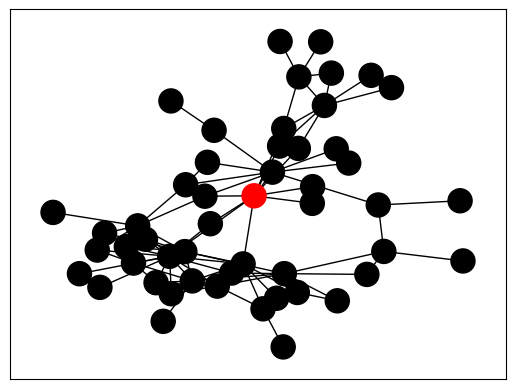

In [20]:
# Map node names to colors: 'red' for 'EHJ' and 'black' for everything else
colors = ['red' if node == 'EHJ' else 'black' for node in G]

# Draw the network using the color list
nx.draw_networkx(G, node_color=colors, with_labels=False)

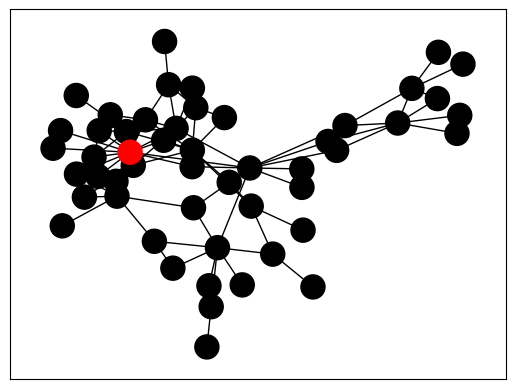

In [21]:
colors = ['red' if node == 'OJSR' else 'black' for node in G]
nx.draw_networkx(G, node_color=colors, with_labels=False)

Now, I'll remove EHJ from the network and see what happens.

In [22]:
G2 = G.copy()
G2.remove_node('EHJ')

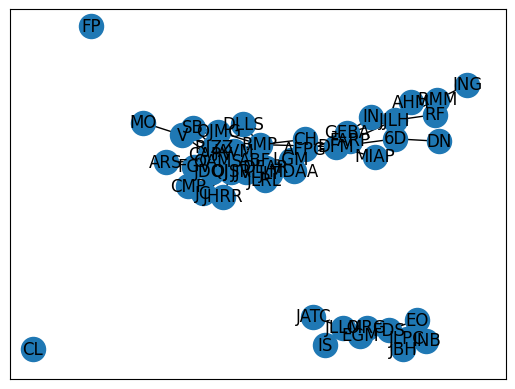

In [23]:
nx.draw_networkx(G2)

In [24]:
triadclos = nx.transitivity(G2)
triadclos

0.30071599045346065

In [26]:
print(f"Average degree: {sum(dict(G2.degree()).values()) / G2.number_of_nodes():.2f}")

Average degree: 3.32


In [25]:
degree_dict2 = dict(G2.degree(G2.nodes()))
nx.set_node_attributes(G2, degree_dict2, 'degree')
sorted_degree2 = sorted(degree_dict2.items(), key=itemgetter(1), reverse=True)
sorted_degree2

[('OJSR', 15),
 ('LGM', 10),
 ('OAMS', 9),
 ('ABF', 8),
 ('RJZZ', 8),
 ('RMP', 8),
 ('CAPV', 7),
 ('FDS', 7),
 ('JJLH', 7),
 ('JJVL', 5),
 ('JLLO', 5),
 ('OJMG', 5),
 ('V', 5),
 ('DFM', 4),
 ('JDQJ', 4),
 ('6D', 3),
 ('DEAR', 3),
 ('FGV', 3),
 ('GEBA', 3),
 ('JAVM', 3),
 ('JLRL', 3),
 ('JLT', 3),
 ('SB', 3),
 ('CH', 2),
 ('DLLS', 2),
 ('EGM', 2),
 ('FARP', 2),
 ('IN', 2),
 ('JBH', 2),
 ('JLPC', 2),
 ('MDAA', 2),
 ('MRG', 2),
 ('RMM', 2),
 ('AFPG', 1),
 ('AHM', 1),
 ('ARS', 1),
 ('CMP', 1),
 ('DN', 1),
 ('EO', 1),
 ('INB', 1),
 ('ING', 1),
 ('IS', 1),
 ('JATC', 1),
 ('JC', 1),
 ('JHRR', 1),
 ('MIAP', 1),
 ('MO', 1),
 ('RF', 1),
 ('CL', 0),
 ('FP', 0)]

Looks pretty effective.  We now have two networks, both smaller than the original.  But let's see what it looks like without OJSR.

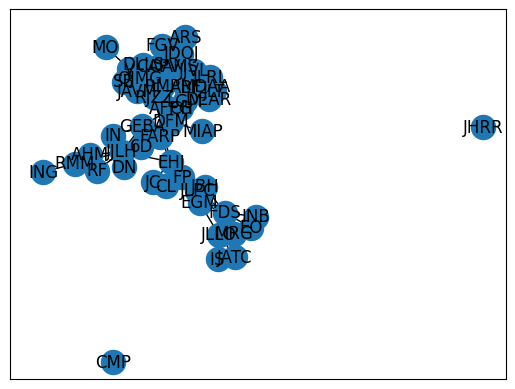

In [27]:
G3 = G.copy()
G3.remove_node('OJSR')
nx.draw_networkx(G3)

In [28]:
triadclos = nx.transitivity(G3)
triadclos

0.22641509433962265

In [30]:
print(f"Average degree: {sum(dict(G3.degree()).values()) / G3.number_of_nodes():.2f}")

Average degree: 3.08


In [29]:
degree_dict3 = dict(G3.degree(G3.nodes()))
nx.set_node_attributes(G3, degree_dict2, 'degree')
sorted_degree3 = sorted(degree_dict3.items(), key=itemgetter(1), reverse=True)
sorted_degree3

[('EHJ', 9),
 ('LGM', 9),
 ('JJLH', 8),
 ('OAMS', 8),
 ('RJZZ', 8),
 ('RMP', 8),
 ('ABF', 7),
 ('FDS', 7),
 ('CAPV', 6),
 ('JLLO', 5),
 ('OJMG', 5),
 ('V', 5),
 ('DFM', 4),
 ('JJVL', 4),
 ('6D', 3),
 ('EGM', 3),
 ('FARP', 3),
 ('GEBA', 3),
 ('JBH', 3),
 ('JDQJ', 3),
 ('JLPC', 3),
 ('SB', 3),
 ('CH', 2),
 ('DEAR', 2),
 ('DLLS', 2),
 ('FGV', 2),
 ('IN', 2),
 ('JAVM', 2),
 ('JLRL', 2),
 ('JLT', 2),
 ('MDAA', 2),
 ('MRG', 2),
 ('RMM', 2),
 ('AFPG', 1),
 ('AHM', 1),
 ('ARS', 1),
 ('CL', 1),
 ('DN', 1),
 ('EO', 1),
 ('FP', 1),
 ('INB', 1),
 ('ING', 1),
 ('IS', 1),
 ('JATC', 1),
 ('JC', 1),
 ('MIAP', 1),
 ('MO', 1),
 ('RF', 1),
 ('CMP', 0),
 ('JHRR', 0)]

I was wrong.  OJSR is the better target.  With them gone, there is a greater decrease in average degree, as well as larger decreases in the degrees of individual nodes.  The graph is no longer connected.

However, without removing EHJ, we don't see the separation of that smaller network, which I think might be important.  So, if we could take out both of them, that might be best.  Let's see what that looks like.

In [31]:
G4 = G.copy()
G4.remove_node('EHJ','OJSR')
nx.draw_networkx(G4)

TypeError: Graph.remove_node() takes 2 positional arguments but 3 were given

Another assist from Gemini to tell me that there is a separate method for removing more than one node at a time.

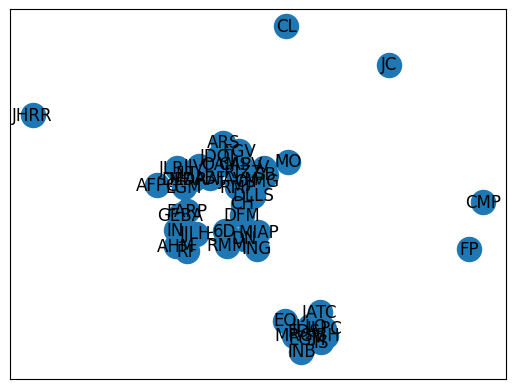

In [32]:
G4 = G.copy()
G4.remove_nodes_from(['EHJ','OJSR'])
nx.draw_networkx(G4)

In [33]:
triadclos = nx.transitivity(G4)
triadclos

0.25384615384615383

In [35]:
print(f"Average degree: {sum(dict(G4.degree()).values()) / G4.number_of_nodes():.2f}")

Average degree: 2.78


In [34]:
degree_dict4 = dict(G4.degree(G4.nodes()))
nx.set_node_attributes(G4, degree_dict4, 'degree')
sorted_degree4 = sorted(degree_dict4.items(), key=itemgetter(1), reverse=True)
sorted_degree4

[('LGM', 9),
 ('OAMS', 8),
 ('RMP', 8),
 ('ABF', 7),
 ('FDS', 7),
 ('JJLH', 7),
 ('RJZZ', 7),
 ('CAPV', 6),
 ('JLLO', 5),
 ('OJMG', 5),
 ('V', 5),
 ('DFM', 4),
 ('JJVL', 4),
 ('6D', 3),
 ('GEBA', 3),
 ('JDQJ', 3),
 ('SB', 3),
 ('CH', 2),
 ('DEAR', 2),
 ('DLLS', 2),
 ('EGM', 2),
 ('FARP', 2),
 ('FGV', 2),
 ('IN', 2),
 ('JAVM', 2),
 ('JBH', 2),
 ('JLPC', 2),
 ('JLRL', 2),
 ('JLT', 2),
 ('MDAA', 2),
 ('MRG', 2),
 ('RMM', 2),
 ('AFPG', 1),
 ('AHM', 1),
 ('ARS', 1),
 ('DN', 1),
 ('EO', 1),
 ('INB', 1),
 ('ING', 1),
 ('IS', 1),
 ('JATC', 1),
 ('MIAP', 1),
 ('MO', 1),
 ('RF', 1),
 ('CL', 0),
 ('CMP', 0),
 ('FP', 0),
 ('JC', 0),
 ('JHRR', 0)]

Eliminating both EHJ and OJSR will have the biggest impact on the netowrk.

Also, while this data cannot provide further answers, I do wonder if the smaller network created from the removal of EHJ represents the money launderers mentioned in the introduction.  If that's the case, then separating them from the main network of smugglers might have a much more crippling effect than this information suggests.  It would also make it essential to remove EHJ, rather than just OJSR, who is the more obvious target.